In [1]:
cd ./wrkDir/s19/s19-1

/work/xiangchong.li/work/galSim-HSC/s19/s19-1


In [9]:
%pylab inline
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import sim_analysis_utilities as utilities
from scipy.interpolate import griddata

import matplotlib
import matplotlib.pyplot as plt

import logging
logging.basicConfig(filename='6-ReGaus_selBias.log',level=logging.INFO)

anaDir='./anaCat_newS19Mask/'
pltDir='./plot/sanityTest_withZ/'
assert os.path.isdir(anaDir)
if not os.path.isdir(pltDir):
    os.mkdir(pltDir)
inFname=os.path.join(anaDir,'allSim.h5')

Populating the interactive namespace from numpy and matplotlib


$$\hat{g}_1=\frac{\sum_i w_i e_{1,i}}{2R(1+\hat{m}) \sum_i w_i}-\frac{\hat{c}_1}{1+\hat{m}}$$

$$R=H(\rm{SNR},\rm{res}) \times I(z)$$
$$m=F(\rm{SNR},\rm{res}) \times G(z)$$

In [10]:
def get_mc_bins(shearBinName,nbin_1d):
    outcomes=np.load(shearBinName)

    nsim   =   len(outcomes)
    psf_e1 =   np.zeros(nsim)
    psf_e2 =   np.zeros(nsim)
    weight =   np.zeros(nsim)
    g1_true=   np.zeros(nsim)
    g2_true=   np.zeros(nsim)
    g1_bins=   np.zeros((nbin_1d,nsim))
    g2_bins=   np.zeros((nbin_1d,nsim))
    sigma_g_bins=   np.zeros((nbin_1d,nsim))

    for iout,outcome in enumerate(outcomes):
        g1_true[iout]  =   outcome[0]
        g2_true[iout]  =   outcome[1]
        g1_bins[:,iout]  =   outcome[2]
        g2_bins[:,iout]  =   outcome[3]
        sigma_g_bins[:,iout]  =   outcome[4]
        psf_e1[iout]  =   outcome[5]
        psf_e2[iout]  =   outcome[6]
        weight[iout]  =   outcome[7]

    m1_bins    =   np.zeros(nbin_1d)
    a1_bins    =   np.zeros(nbin_1d)
    sigm1_bins =   np.zeros(nbin_1d)
    siga1_bins =   np.zeros(nbin_1d)

    # For each of the sliding bins in SNR/resolution.
    for j in range(nbin_1d):
        sigma_vals = sigma_g_bins[j,:]
        division_val = np.sqrt(weight)
        division_val[division_val<1.e-6] = 1.e-6
        sigma_vals /= division_val
        # remove unrealistic sim
        tmp_use = (sigma_vals < 1.e+10)
        # get multiplicative bias and additive bias
        m1_bins[j],a1_bins[j], \
        sigm1_bins[j],siga1_bins[j]= \
            utilities.get_m_c_a(g1_bins[j,tmp_use],
                                g2_bins[j,tmp_use],
                                g1_true[tmp_use],
                                g2_true[tmp_use],
                                psf_e1[tmp_use],
                                psf_e2[tmp_use],
                                sigma_vals[tmp_use],
                                separate_components=False)
    
    return m1_bins,a1_bins,sigm1_bins,siga1_bins

def makePlotSelBias(obsname,data=None):
    nbin_1d=3
    if obsname=="mag":
        min_obs=21.5
        max_obs=24.5
        obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
        xlabel='CModel Mag'
    elif obsname=="magA10":
        min_obs=22.5
        max_obs=25.5
        obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
        xlabel='Aperture Mag'
    elif obsname=="res":
        min_obs=0.3
        max_obs=1.0
        obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
        xlabel='reGaus resolution'
    elif obsname=="snr":
        min_obs=10.
        max_obs=100.
        obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
        xlabel='CModel SNR'
    elif obsname=="COSMOS_Z":
        obs_bounds  =   np.array([0.0,0.5,1.0,1.5,2.5,4.])
        nbin_1d     =   len(obs_bounds)-1
        xlabel='COSMOS redshift'
    elif obsname=="mizuki_Z":
        obs_bounds  =   np.array([0.0,0.5,1.0,1.5,2.5,4.])
        nbin_1d     =   len(obs_bounds)-1
        xlabel='Mizuki redshift'
    elif obsname=="COSMOS15_Z":
        obs_bounds  =   np.array([0.0,0.5,1.0,1.5,2.5,4.])
        nbin_1d     =   len(obs_bounds)-1
        xlabel='COSMOS redshift'
    elif obsname=="COSMOS_Mag":
        min_obs=21.5
        max_obs=24.5
        obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
        xlabel='COSMOS Mag'
    elif obsname=="fwhm":
        min_obs=0.3
        max_obs=0.9
        obs_bounds  =   np.linspace(min_obs,max_obs,nbin_1d+1)
        xlabel='FWHM (arcsec)'
    obs_lowers  =   obs_bounds[:-1]
    obs_uppers  =   obs_bounds[1:]
    if data is None:
        obs_ave     =   (obs_uppers+obs_lowers)/2.
    else:
        obs_ave=[]
        obs=data[obsname]
        for il,iu in zip(obs_lowers,obs_uppers):
            msk=(obs>=il)&(obs<iu)
            obs_ave.append(np.average(obs[msk]))
        obs_ave=np.array(obs_ave)
            

    shearBinName=   os.path.join(pltDir,'shear_sanitytest_%s_90rot.npy' %obsname)
    m1,a1,sigm1,siga1=get_mc_bins(shearBinName,nbin_1d)

    fig = plt.figure(figsize=(12,5))
    ax = fig.add_subplot(1,2,1)
    ax.errorbar(obs_ave, m1,sigm1)
    ax.set_xlabel(xlabel,fontsize=15)
    ax.set_ylabel(r'$\delta m$',fontsize=15)
    ax.set_title('Multiplicative bias',fontsize=20)
    plt.grid()

    ax = fig.add_subplot(1,2,2)
    ax.errorbar(obs_ave, a1,siga1)
    ax.set_xlabel(xlabel,fontsize=15)
    ax.set_ylabel(r'$\delta a$',fontsize=15)
    ax.set_title('Additive bias',fontsize=20)
    plt.grid()
    plt.tight_layout()
    plt.savefig(os.path.join(pltDir,'calibration_residual_%s.eps' %(obsname)))
    return obs_ave,m1,sigm1,a1,siga1

## Calibration as function of redshift

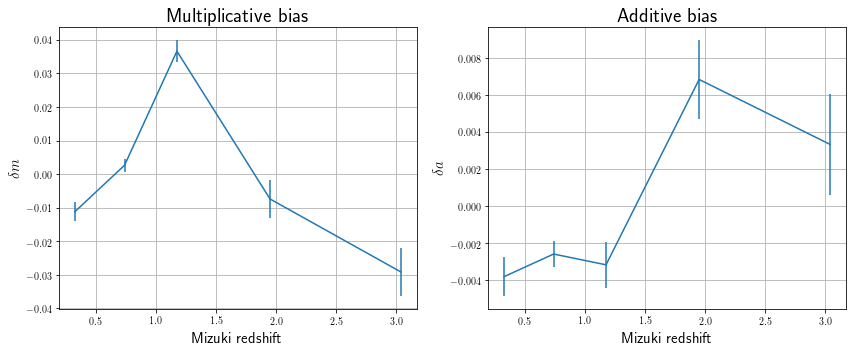

In [32]:
z_grid,m_res,m_sig,a_res,a_sig=makePlotSelBias('mizuki_Z',data)
if False:
    out_data=list(zip(z_grid,m_res,m_sig,a_res,a_sig))
    mcDeltaBinTab    =   pd.DataFrame(data=out_data,columns=('z','dm','mSigma','da','aSigma'))
    mcDeltaBinTab.to_csv(os.path.join(pltDir,'mizuki_z_bin_dm_da_2d.csv'))

## Modelled Properties

(array([25., 55., 85.]),
 array([-0.00297714, -0.00568782, -0.0033531 ]),
 array([0.00280876, 0.00203929, 0.0019121 ]),
 array([-0.00067832,  0.00128453,  0.00159856]),
 array([0.00105943, 0.00077225, 0.00072467]))

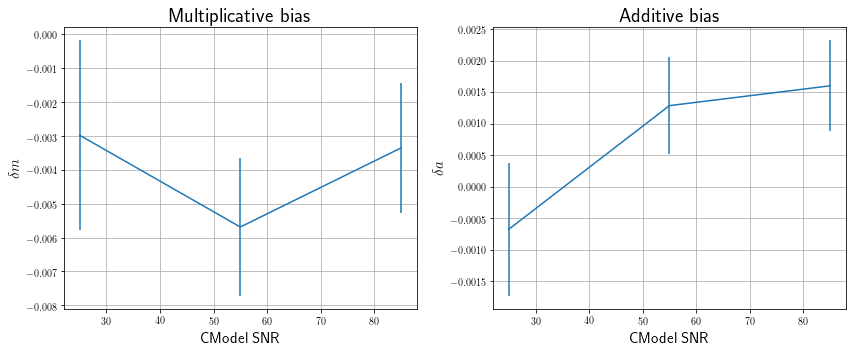

In [12]:
makePlotSelBias('snr')

(array([0.41666667, 0.65      , 0.88333333]),
 array([-0.00308179, -0.00348514, -0.00227409]),
 array([0.00265024, 0.00199388, 0.00261071]),
 array([0.00067824, 0.00118003, 0.00012447]),
 array([0.00102619, 0.0007527 , 0.00093566]))

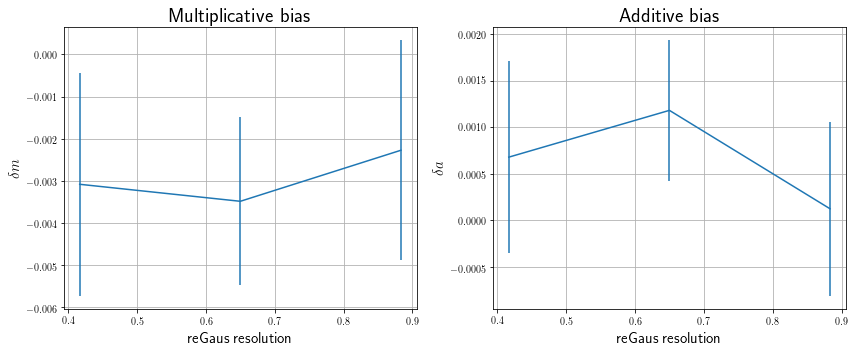

In [13]:
makePlotSelBias('res')

## Marginalized Properties

(array([22., 23., 24.]),
 array([ 0.01160396, -0.00812196, -0.00397549]),
 array([0.00137358, 0.00168361, 0.0027494 ]),
 array([ 0.00215622,  0.00103647, -0.00076541]),
 array([0.00052212, 0.00063984, 0.001037  ]))

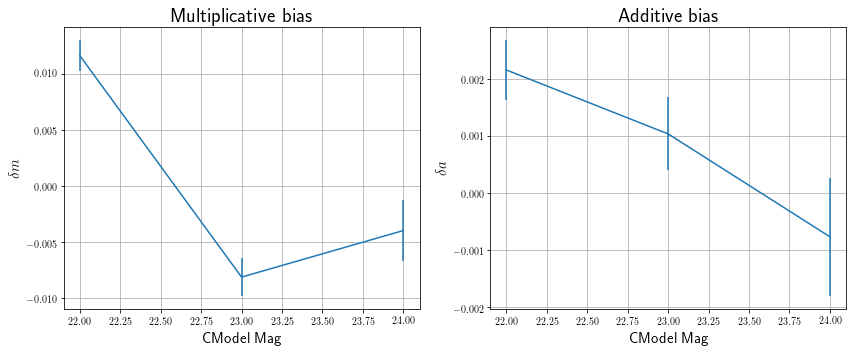

In [16]:
makePlotSelBias('mag')

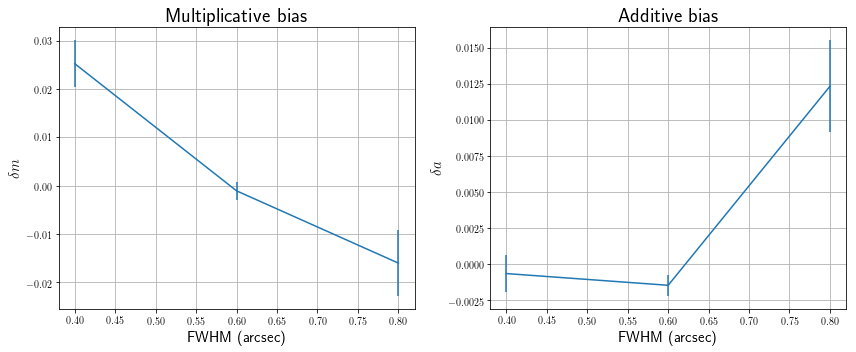

In [23]:
makePlotSelBias('fwhm')

0.9824044658858403


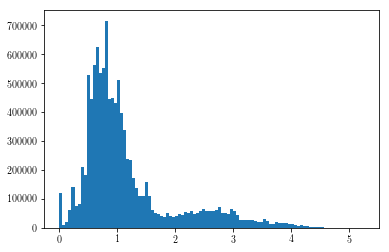

In [5]:
dataF =   pd.read_hdf(inFname,mode='r')
dataF =   dataF[dataF['wlmask_90rot']]
mask=((dataF['mizuki_Z']>-1))
data=dataF[mask]
print(np.sum(mask)/len(dataF))
a=plt.hist(dataF['mizuki_Z'][mask],bins=100)

In [6]:
indexList=  data.index.levels[1]
outData=[]
for index in indexList:
    catalog =   data.xs(index,level='isim').to_records(index=False)
    reweight     =   catalog['weight'][0]
    if len(catalog)<50 or reweight<1.e-6:
        continue
    # Force the same weight and Response
    e_rms = utilities.get_erms_model(catalog)
    shape_weights = utilities.get_weight_model(catalog)*catalog['weight']
    
    # True shear
    g1_true, g2_true= utilities.get_true_shear(catalog[0])
    # PSF shapes
    psf_e1, psf_e2  =   utilities.get_psf_ellip(catalog[0])
    # Shear Estimation
    e1,e2   =   utilities.get_gal_ellip(catalog)
    shear_num_1 = np.sum(shape_weights * e1)
    shear_num_2 = np.sum(shape_weights * e2)
    sum_weight = np.sum(shape_weights)
    # Calibration
    model_m = utilities.get_m_model(catalog,weight_bias=True,photo_z_dep=True)

    model_c1,model_c2 = utilities.get_c_model(catalog,weight_bias=True,photo_z_dep=True)
    bias_num = np.sum(shape_weights*model_m)
    add_num_1 = np.sum(shape_weights*model_c1)
    add_num_2 = np.sum(shape_weights*model_c2)
    bias = bias_num / sum_weight
    resp_num = np.sum(shape_weights * e_rms**2)
    responsivity = 1.0 - resp_num/sum_weight

    g1 = shear_num_1 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_1/((1.0+bias)*sum_weight)
    g2 = shear_num_2 / (2.0*responsivity*sum_weight*(1.0+bias)) \
        - add_num_2/((1.0+bias)*sum_weight)
    sigma= 0.25/np.sqrt(len(catalog))
    
    oDat    =   (g1_true,g2_true,g1,g2,sigma,psf_e1,psf_e2,reweight)
    outData.append(oDat)

In [7]:
odf=pd.DataFrame(outData,columns=('g1_true','g2_true','g1','g2','sigma','psf_e1','psf_e2','reweight')).to_records()
division_val = np.sqrt(odf['reweight'])
division_val[division_val<1.e-6] = 1.e-6
odf['sigma'] /= division_val
# remove unrealistic sim
odf=odf[(odf['sigma'] < 1.e+10)]
# get multiplicative bias and additive bias
m1,a1,sigm1,siga1= utilities.get_m_c_a(
    odf['g1'],odf['g2'],
    odf['g1_true'],odf['g2_true'],
    odf['psf_e1'],odf['psf_e2'],
    odf['sigma'],separate_components=False)
print('m = %.4f +/- %.4f' % (m1, sigm1))
print('a = %.4f +/- %.4f' % (a1, siga1))

m = -0.0022 +/- 0.0017
a = 0.0005 +/- 0.0006
